# 05 - Four-Stage ECG Convolutional Neural Network

### 5.1. Objective

Evaluate how progressively adding temporal, rhythm, and morphology
information affects a one-dimensional convolutional neural network
for ECG heartbeat classification.

The CNN is evaluated using the same four information stages used for
Logistic Regression, Random Forest, and XGBoost:

1. ECG
2. ECG + 6RR
3. ECG + 13Context
4. ECG + 21 engineered features

### Input Structure

The 255-sample ECG heartbeat is always processed by the convolutional
waveform branch.

For Stages 2 to 4, the additional engineered features are processed
through a separate auxiliary feature branch and fused with the learned
ECG representation before classification.

### Experimental Controls

All four CNN stages use:

- the same canonical heartbeat rows
- the same N/S/V/F labels
- the same fixed five DS1 record-grouped cross-validation folds
- the same convolutional backbone
- the same optimizer
- the same learning rate
- the same batch size
- the same weighted cross-entropy formulation
- the same maximum epoch budget
- the same model-selection criterion

Macro-F1 is the primary validation metric.
Balanced accuracy is used as the secondary criterion.

DS2 is used only for evaluation of the final models.

In [1]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import copy
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader,
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
)

from sklearn.utils.class_weight import (
    compute_class_weight,
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42


def set_seed(seed):
    """
    Reset random-number generators before each model
    initialization for reproducible CNN experiments.
    """

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )


    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            seed
        )


set_seed(
    SEED
)


print(
    "Base random seed:",
    SEED
)

Base random seed: 42


In [2]:
# ============================================================
# SECTION 1: FIND PROJECT ROOT
# ============================================================

CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = CURRENT_DIR


while not (
    PROJECT_ROOT
    / "requirements.txt"
).exists():

    if (
        PROJECT_ROOT.parent
        == PROJECT_ROOT
    ):

        raise FileNotFoundError(
            "Could not locate the ECG-ML project root."
        )

    PROJECT_ROOT = (
        PROJECT_ROOT.parent
    )


# ============================================================
# SECTION 2: DEFINE PROJECT DIRECTORIES
# ============================================================

DATA_DIR = (
    PROJECT_ROOT
    / "data"
)

PROCESSED_DATA_DIR = (
    DATA_DIR
    / "processed"
)

MODELS_DIR = (
    PROJECT_ROOT
    / "models"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
)

METRICS_DIR = (
    RESULTS_DIR
    / "metrics"
)

FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
)


MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# SECTION 3: DEFINE REQUIRED INPUT FILES
# ============================================================

REQUIRED_FILES = {

    "ds1_ecg":
        PROCESSED_DATA_DIR
        / "X_ds1_ecg.npy",

    "ds2_ecg":
        PROCESSED_DATA_DIR
        / "X_ds2_ecg.npy",

    "ds1_rr6":
        PROCESSED_DATA_DIR
        / "X_ds1_rr6.npy",

    "ds2_rr6":
        PROCESSED_DATA_DIR
        / "X_ds2_rr6.npy",

    "ds1_context13":
        PROCESSED_DATA_DIR
        / "X_ds1_context13.npy",

    "ds2_context13":
        PROCESSED_DATA_DIR
        / "X_ds2_context13.npy",

    "ds1_engineered21":
        PROCESSED_DATA_DIR
        / "X_ds1_engineered21.npy",

    "ds2_engineered21":
        PROCESSED_DATA_DIR
        / "X_ds2_engineered21.npy",

    "y_ds1":
        PROCESSED_DATA_DIR
        / "y_ds1.npy",

    "y_ds2":
        PROCESSED_DATA_DIR
        / "y_ds2.npy",

    "ds1_metadata":
        PROCESSED_DATA_DIR
        / "ds1_metadata.csv",

    "ds2_metadata":
        PROCESSED_DATA_DIR
        / "ds2_metadata.csv",

    "fixed_folds":
        PROCESSED_DATA_DIR
        / "ds1_cv_record_folds.csv",

    "rr6_names":
        PROCESSED_DATA_DIR
        / "rr6_feature_names.npy",

    "context13_names":
        PROCESSED_DATA_DIR
        / "context13_feature_names.npy",

    "engineered21_names":
        PROCESSED_DATA_DIR
        / "engineered21_feature_names.npy",
}


# ============================================================
# SECTION 4: VERIFY REQUIRED FILES
# ============================================================

for (
    file_name,
    file_path

) in REQUIRED_FILES.items():

    if not file_path.exists():

        raise FileNotFoundError(
            f"Required file '{file_name}' "
            f"was not found:\n{file_path}"
        )


# ============================================================
# SECTION 5: LOAD CANONICAL ECG
# ============================================================

X_ds1_ecg = np.load(
    REQUIRED_FILES[
        "ds1_ecg"
    ]
).astype(
    np.float32
)


X_ds2_ecg = np.load(
    REQUIRED_FILES[
        "ds2_ecg"
    ]
).astype(
    np.float32
)


# ============================================================
# SECTION 6: LOAD RR6
# ============================================================

X_ds1_rr6 = np.load(
    REQUIRED_FILES[
        "ds1_rr6"
    ]
).astype(
    np.float32
)


X_ds2_rr6 = np.load(
    REQUIRED_FILES[
        "ds2_rr6"
    ]
).astype(
    np.float32
)


# ============================================================
# SECTION 7: LOAD CONTEXT13
# ============================================================

X_ds1_context13 = np.load(
    REQUIRED_FILES[
        "ds1_context13"
    ]
).astype(
    np.float32
)


X_ds2_context13 = np.load(
    REQUIRED_FILES[
        "ds2_context13"
    ]
).astype(
    np.float32
)


# ============================================================
# SECTION 8: LOAD ENGINEERED21
# ============================================================

X_ds1_engineered21 = np.load(
    REQUIRED_FILES[
        "ds1_engineered21"
    ]
).astype(
    np.float32
)


X_ds2_engineered21 = np.load(
    REQUIRED_FILES[
        "ds2_engineered21"
    ]
).astype(
    np.float32
)


# ============================================================
# SECTION 9: LOAD LABELS
# ============================================================

y_ds1 = (
    np.load(
        REQUIRED_FILES[
            "y_ds1"
        ]
    )
    .astype(str)
)


y_ds2 = (
    np.load(
        REQUIRED_FILES[
            "y_ds2"
        ]
    )
    .astype(str)
)


# ============================================================
# SECTION 10: LOAD METADATA
# ============================================================

ds1_metadata = pd.read_csv(
    REQUIRED_FILES[
        "ds1_metadata"
    ],
    dtype={
        "beat_uid": str,
        "record_id": str,
    }
)


ds2_metadata = pd.read_csv(
    REQUIRED_FILES[
        "ds2_metadata"
    ],
    dtype={
        "beat_uid": str,
        "record_id": str,
    }
)


# ============================================================
# SECTION 11: LOAD FEATURE NAMES
# ============================================================

rr6_feature_names = (
    np.load(
        REQUIRED_FILES[
            "rr6_names"
        ]
    )
    .astype(str)
    .tolist()
)


context13_feature_names = (
    np.load(
        REQUIRED_FILES[
            "context13_names"
        ]
    )
    .astype(str)
    .tolist()
)


engineered21_feature_names = (
    np.load(
        REQUIRED_FILES[
            "engineered21_names"
        ]
    )
    .astype(str)
    .tolist()
)


# ============================================================
# SECTION 12: VERIFY ROW ALIGNMENT
# ============================================================

assert (
    len(X_ds1_ecg)
    == len(X_ds1_rr6)
    == len(X_ds1_context13)
    == len(X_ds1_engineered21)
    == len(y_ds1)
    == len(ds1_metadata)
)


assert (
    len(X_ds2_ecg)
    == len(X_ds2_rr6)
    == len(X_ds2_context13)
    == len(X_ds2_engineered21)
    == len(y_ds2)
    == len(ds2_metadata)
)


# ============================================================
# SECTION 13: VERIFY DIMENSIONS
# ============================================================

assert X_ds1_ecg.shape[1] == 255
assert X_ds2_ecg.shape[1] == 255

assert X_ds1_rr6.shape[1] == 6
assert X_ds2_rr6.shape[1] == 6

assert X_ds1_context13.shape[1] == 13
assert X_ds2_context13.shape[1] == 13

assert X_ds1_engineered21.shape[1] == 21
assert X_ds2_engineered21.shape[1] == 21


# ============================================================
# SECTION 14: VERIFY FEATURE NAME COUNTS
# ============================================================

assert len(
    rr6_feature_names
) == 6

assert len(
    context13_feature_names
) == 13

assert len(
    engineered21_feature_names
) == 21


# ============================================================
# SECTION 15: VERIFY LABEL ALIGNMENT
# ============================================================

assert np.array_equal(
    y_ds1,

    ds1_metadata[
        "class"
    ]
    .astype(str)
    .to_numpy()
)


assert np.array_equal(
    y_ds2,

    ds2_metadata[
        "class"
    ]
    .astype(str)
    .to_numpy()
)


# ============================================================
# SECTION 16: VERIFY UNIQUE HEARTBEAT IDS
# ============================================================

assert (
    ds1_metadata[
        "beat_uid"
    ]
    .is_unique
)


assert (
    ds2_metadata[
        "beat_uid"
    ]
    .is_unique
)


# ============================================================
# SECTION 17: DEFINE CNN STAGES
# ============================================================

STAGE_NAMES = [
    "ECG",
    "ECG+6RR",
    "ECG+13Context",
    "ECG+21",
]


CNN_STAGE_DATA = {

    "ECG": {

        "X_ds1_aux":
            np.empty(
                (
                    len(y_ds1),
                    0,
                ),
                dtype=np.float32,
            ),

        "X_ds2_aux":
            np.empty(
                (
                    len(y_ds2),
                    0,
                ),
                dtype=np.float32,
            ),

        "feature_names":
            [],
    },


    "ECG+6RR": {

        "X_ds1_aux":
            X_ds1_rr6,

        "X_ds2_aux":
            X_ds2_rr6,

        "feature_names":
            rr6_feature_names,
    },


    "ECG+13Context": {

        "X_ds1_aux":
            X_ds1_context13,

        "X_ds2_aux":
            X_ds2_context13,

        "feature_names":
            context13_feature_names,
    },


    "ECG+21": {

        "X_ds1_aux":
            X_ds1_engineered21,

        "X_ds2_aux":
            X_ds2_engineered21,

        "feature_names":
            engineered21_feature_names,
    },
}


# ============================================================
# SECTION 18: VERIFY STAGE DIMENSIONS
# ============================================================

EXPECTED_AUX_DIMENSIONS = {
    "ECG": 0,
    "ECG+6RR": 6,
    "ECG+13Context": 13,
    "ECG+21": 21,
}


for stage_name in STAGE_NAMES:

    assert (
        CNN_STAGE_DATA[
            stage_name
        ][
            "X_ds1_aux"
        ].shape
        ==
        (
            len(y_ds1),
            EXPECTED_AUX_DIMENSIONS[
                stage_name
            ],
        )
    )


    assert (
        CNN_STAGE_DATA[
            stage_name
        ][
            "X_ds2_aux"
        ].shape
        ==
        (
            len(y_ds2),
            EXPECTED_AUX_DIMENSIONS[
                stage_name
            ],
        )
    )


# ============================================================
# SECTION 19: DISPLAY SUMMARY
# ============================================================

stage_summary_df = pd.DataFrame(
    [
        {
            "stage":
                stage_name,

            "ecg_samples":
                255,

            "auxiliary_features":
                EXPECTED_AUX_DIMENSIONS[
                    stage_name
                ],
        }

        for stage_name
        in STAGE_NAMES
    ]
)


display(
    stage_summary_df
)

,stage,ecg_samples,auxiliary_features
0,ECG,255,0
1,ECG+6RR,255,6
2,ECG+13Context,255,13
3,ECG+21,255,21


### 5.2. Encode Heartbeat Labels

Use one fixed N/S/V/F class order for every CNN stage.

In [3]:
# ============================================================
# DEFINE FIXED CLASS ORDER
# ============================================================

CLASS_NAMES = [
    "N",
    "S",
    "V",
    "F",
]


class_to_index = {
    class_name: index

    for (
        index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    )
}


index_to_class = {
    index: class_name

    for (
        class_name,
        index
    ) in class_to_index.items()
}


# ============================================================
# ENCODE DS1 LABELS
# ============================================================

y_ds1_encoded = np.asarray(
    [
        class_to_index[
            str(label)
        ]

        for label
        in y_ds1
    ],
    dtype=np.int64,
)


# ============================================================
# ENCODE DS2 LABELS
# ============================================================

y_ds2_encoded = np.asarray(
    [
        class_to_index[
            str(label)
        ]

        for label
        in y_ds2
    ],
    dtype=np.int64,
)


# ============================================================
# VERIFY ENCODING
# ============================================================

assert set(
    np.unique(
        y_ds1_encoded
    )
) == set(
    range(
        len(
            CLASS_NAMES
        )
    )
)


assert set(
    np.unique(
        y_ds2_encoded
    )
) == set(
    range(
        len(
            CLASS_NAMES
        )
    )
)


print(
    "Class mapping:"
)

print(
    class_to_index
)

Class mapping:
{'N': 0, 'S': 1, 'V': 2, 'F': 3}


### 5.3. Load the Fixed DS1 Cross-Validation Folds

Use exactly the same five record-grouped DS1 folds created in Notebook 02
and used by Logistic Regression, Random Forest, and XGBoost.

No new folds are generated in this notebook.

In [4]:
# ============================================================
# LOAD AND VERIFY FIXED DS1 CROSS-VALIDATION FOLDS
# ============================================================

N_SPLITS = 5


# ============================================================
# LOAD FIXED RECORD-LEVEL ASSIGNMENT
# ============================================================

FOLD_ASSIGNMENT_PATH = (
    REQUIRED_FILES[
        "fixed_folds"
    ]
)


ds1_record_folds = pd.read_csv(
    FOLD_ASSIGNMENT_PATH,
    dtype={
        "record_id": str,
        "cv_fold": int,
    }
)


# ============================================================
# VERIFY RECORD-LEVEL ASSIGNMENT
# ============================================================

assert (
    len(
        ds1_record_folds
    )
    == 22
)


assert (
    ds1_record_folds[
        "record_id"
    ]
    .is_unique
)


assert set(
    ds1_record_folds[
        "cv_fold"
    ]
) == {
    1,
    2,
    3,
    4,
    5,
}


# ============================================================
# CREATE RECORD-TO-FOLD MAP
# ============================================================

record_to_fold = dict(
    zip(
        ds1_record_folds[
            "record_id"
        ],

        ds1_record_folds[
            "cv_fold"
        ],
    )
)


groups = (
    ds1_metadata[
        "record_id"
    ]
    .astype(str)
    .to_numpy()
)


sample_folds = (
    ds1_metadata[
        "record_id"
    ]
    .map(
        record_to_fold
    )
)


assert (
    sample_folds
    .notna()
    .all()
)


sample_folds = (
    sample_folds
    .to_numpy(
        dtype=int
    )
)


# ============================================================
# VERIFY AGAINST SAVED METADATA
# ============================================================

assert np.array_equal(
    sample_folds,

    ds1_metadata[
        "cv_fold"
    ]
    .to_numpy(
        dtype=int
    )
)


# ============================================================
# CREATE FIVE TRAIN / VALIDATION SPLITS
# ============================================================

cv_folds = []


for fold_number in range(
    1,
    N_SPLITS + 1
):

    train_indices = np.where(
        sample_folds
        != fold_number
    )[0]


    val_indices = np.where(
        sample_folds
        == fold_number
    )[0]


    cv_folds.append(
        (
            train_indices,
            val_indices,
        )
    )


# ============================================================
# VERIFY RECORD ISOLATION AND CLASS COVERAGE
# ============================================================

for fold_number, (
    train_indices,
    val_indices

) in enumerate(
    cv_folds,
    start=1
):

    train_records = set(
        groups[
            train_indices
        ]
    )


    val_records = set(
        groups[
            val_indices
        ]
    )


    assert (
        train_records
        .isdisjoint(
            val_records
        )
    )


    y_val = (
        y_ds1_encoded[
            val_indices
        ]
    )


    for class_index in range(
        len(
            CLASS_NAMES
        )
    ):

        assert np.sum(
            y_val
            == class_index
        ) > 0


    print(
        f"Fold {fold_number}: "
        f"{len(train_records)} train records | "
        f"{len(val_records)} validation records | "
        f"PASS"
    )


print(
    "\nLoaded the same fixed folds used by "
    "the conventional ML experiments."
)

Fold 1: 17 train records | 5 validation records | PASS
Fold 2: 17 train records | 5 validation records | PASS
Fold 3: 18 train records | 4 validation records | PASS
Fold 4: 18 train records | 4 validation records | PASS
Fold 5: 18 train records | 4 validation records | PASS

Loaded the same fixed folds used by the conventional ML experiments.


### 5.4. Auxiliary-Feature Preprocessing and Tensor Construction

For stages containing auxiliary features, median imputation and
standardization are fitted using only the training records in each
cross-validation fold.

The ECG-only stage has no auxiliary preprocessing.

In [5]:
# ============================================================
# AUXILIARY-FEATURE PREPROCESSING HELPERS
# ============================================================

def fit_feature_preprocessor(
    training_features
):
    """
    Fit median imputation and standardization using
    the current training fold only.

    ECG-only stage:
        returns (None, None)
    """

    # --------------------------------------------------------
    # ECG-only stage has zero auxiliary columns
    # --------------------------------------------------------

    if (
        training_features.shape[1]
        == 0
    ):

        return (
            None,
            None,
        )


    # --------------------------------------------------------
    # Fit preprocessing on training rows only
    # --------------------------------------------------------

    imputer = SimpleImputer(
        strategy="median"
    )


    scaler = StandardScaler()


    training_imputed = (
        imputer.fit_transform(
            training_features
        )
    )


    scaler.fit(
        training_imputed
    )


    return (
        imputer,
        scaler,
    )


def transform_features(
    features,
    imputer,
    scaler,
):
    """
    Apply preprocessing fitted on training records only.
    """

    # --------------------------------------------------------
    # ECG-only stage
    # --------------------------------------------------------

    if (
        features.shape[1]
        == 0
    ):

        return features.astype(
            np.float32
        )


    features_imputed = (
        imputer.transform(
            features
        )
    )


    features_scaled = (
        scaler.transform(
            features_imputed
        )
    )


    return features_scaled.astype(
        np.float32
    )


# ============================================================
# PYTORCH DATASET HELPER
# ============================================================

def create_tensor_dataset(
    ecg_beats,
    auxiliary_features,
    labels,
):
    """
    ECG:
        [N, 1, 255]

    Auxiliary features:
        [N, 0], [N, 6], [N, 13], or [N, 21]

    Labels:
        [N]
    """

    ecg_tensor = torch.tensor(
        ecg_beats[
            :,
            None,
            :
        ],
        dtype=torch.float32,
    )


    feature_tensor = torch.tensor(
        auxiliary_features,
        dtype=torch.float32,
    )


    label_tensor = torch.tensor(
        labels,
        dtype=torch.long,
    )


    return TensorDataset(
        ecg_tensor,
        feature_tensor,
        label_tensor,
    )

### 5.5. Create DataLoaders

In [6]:
# ============================================================
# DATALOADER SETTINGS
# ============================================================

BATCH_SIZE = 256


# ============================================================
# CREATE CNN DATA LOADER
# ============================================================

def create_data_loader(
    ecg_beats,
    auxiliary_features,
    labels,
    shuffle,
):
    """
    Build one DataLoader for any of the four CNN stages.
    """

    dataset = create_tensor_dataset(
        ecg_beats,
        auxiliary_features,
        labels,
    )


    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
    )


    return loader


print(
    "Batch size:",
    BATCH_SIZE
)

Batch size: 256


### 5.6. Define the Four-Stage CNN Architecture

The ECG convolutional backbone is identical across all stages.

For ECG-only input, classification is performed directly from the learned
ECG embedding.

For stages with auxiliary features, a feature branch learns an auxiliary
embedding, which is fused with both the learned ECG representation and the
standardized auxiliary features.

In [7]:
# ============================================================
# FOUR-STAGE ECG FEATURE-FUSION CNN
# ============================================================

class ECGFeatureFusionCNN(
    nn.Module
):

    def __init__(
        self,
        num_aux_features,
        num_classes=4,
    ):

        super().__init__()


        self.num_aux_features = (
            num_aux_features
        )


        # ====================================================
        # ECG WAVEFORM BRANCH
        # ====================================================

        self.conv1 = nn.Sequential(

            nn.Conv1d(
                in_channels=1,
                out_channels=32,
                kernel_size=7,
                padding=3,
            ),

            nn.BatchNorm1d(
                32
            ),

            nn.ReLU(),

            nn.MaxPool1d(
                2
            ),
        )


        self.conv2 = nn.Sequential(

            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=5,
                padding=2,
            ),

            nn.BatchNorm1d(
                64
            ),

            nn.ReLU(),

            nn.MaxPool1d(
                2
            ),
        )


        self.conv3 = nn.Sequential(

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1,
            ),

            nn.BatchNorm1d(
                128
            ),

            nn.ReLU(),
        )


        self.global_pool = (
            nn.AdaptiveAvgPool1d(
                1
            )
        )


        # ====================================================
        # OPTIONAL AUXILIARY FEATURE BRANCH
        # ====================================================

        if (
            num_aux_features
            > 0
        ):

            self.feature_branch = nn.Sequential(

                nn.Linear(
                    num_aux_features,
                    64,
                ),

                nn.ReLU(),

                nn.Dropout(
                    0.20
                ),

                nn.Linear(
                    64,
                    32,
                ),

                nn.ReLU(),
            )


            fusion_dim = (
                128
                + 32
                + num_aux_features
            )


        else:

            self.feature_branch = None

            fusion_dim = 128


        # ====================================================
        # CLASSIFICATION HEAD
        # ====================================================

        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                128,
            ),

            nn.ReLU(),

            nn.Dropout(
                0.30
            ),

            nn.Linear(
                128,
                num_classes,
            ),
        )


    def forward(
        self,
        ecg,
        auxiliary_features,
    ):

        # ====================================================
        # ECG BRANCH
        # ====================================================

        ecg_features = self.conv1(
            ecg
        )


        ecg_features = self.conv2(
            ecg_features
        )


        ecg_features = self.conv3(
            ecg_features
        )


        ecg_features = self.global_pool(
            ecg_features
        )


        ecg_features = (
            ecg_features.squeeze(
                -1
            )
        )


        # ====================================================
        # ECG-ONLY STAGE
        # ====================================================

        if (
            self.num_aux_features
            == 0
        ):

            fused_features = (
                ecg_features
            )


        # ====================================================
        # ECG + AUXILIARY FEATURES
        # ====================================================

        else:

            learned_features = (
                self.feature_branch(
                    auxiliary_features
                )
            )


            fused_features = torch.cat(
                [
                    ecg_features,
                    learned_features,
                    auxiliary_features,
                ],
                dim=1,
            )


        # ====================================================
        # CLASSIFICATION
        # ====================================================

        logits = self.classifier(
            fused_features
        )


        return logits

### Select CPU/GPU/MPS

In [8]:
# ============================================================
# SELECT COMPUTE DEVICE
# ============================================================

if torch.cuda.is_available():

    device = torch.device(
        "cuda"
    )

elif (
    hasattr(
        torch.backends,
        "mps"
    )
    and torch.backends.mps.is_available()
):

    device = torch.device(
        "mps"
    )

else:

    device = torch.device(
        "cpu"
    )


print(
    "Using device:",
    device
)

Using device: mps


### Handle class imbalance

In [9]:
# ============================================================
# CLASS-WEIGHT HELPER
# ============================================================

def calculate_class_weights(
    training_labels,
    device,
):
    """
    Calculate balanced class weights using only
    the training portion of the current DS1 fold.
    """

    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(
            len(
                CLASS_NAMES
            )
        ),
        y=training_labels,
    )


    class_weights = torch.tensor(
        class_weights,
        dtype=torch.float32,
        device=device,
    )


    return class_weights


print(
    "Class weights will be calculated "
    "inside each training fold."
)

Class weights will be calculated inside each training fold.


### Initialize CNN

In [10]:
# ============================================================
# MODEL INITIALIZATION HELPER
# ============================================================

LEARNING_RATE = 1e-3


def initialize_model(
    num_aux_features,
    class_weights,
):
    """
    Create a fresh CNN for the requested feature stage.
    """

    model = ECGFeatureFusionCNN(
        num_aux_features=
            num_aux_features,

        num_classes=
            len(
                CLASS_NAMES
            ),
    )


    model = model.to(
        device
    )


    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )


    return (
        model,
        criterion,
        optimizer,
    )


# ============================================================
# DISPLAY PARAMETER COUNTS FOR ALL FOUR STAGES
# ============================================================

model_parameter_rows = []


example_weights = torch.ones(
    len(
        CLASS_NAMES
    ),
    dtype=torch.float32,
    device=device,
)


for stage_name in STAGE_NAMES:

    num_aux_features = (
        EXPECTED_AUX_DIMENSIONS[
            stage_name
        ]
    )


    set_seed(
        SEED
    )


    example_model, _, _ = (
        initialize_model(
            num_aux_features,
            example_weights,
        )
    )


    n_parameters = sum(
        parameter.numel()

        for parameter
        in example_model.parameters()

        if parameter.requires_grad
    )


    model_parameter_rows.append(
        {
            "stage":
                stage_name,

            "auxiliary_features":
                num_aux_features,

            "trainable_parameters":
                n_parameters,
        }
    )


    del example_model


model_parameter_df = pd.DataFrame(
    model_parameter_rows
)


display(
    model_parameter_df
)

,stage,auxiliary_features,trainable_parameters
0,ECG,0,52740
1,ECG+6RR,6,60132
2,ECG+13Context,13,61476
3,ECG+21,21,63012


### Train CNN

In [11]:
# ============================================================
# FOUR-STAGE 5-FOLD CNN DEVELOPMENT
# ============================================================

NUM_EPOCHS = 20


cnn_cv_fold_rows = []

cnn_cv_summary_rows = []

cnn_stage_development = {}


# ============================================================
# LOOP THROUGH FOUR FEATURE STAGES
# ============================================================

for stage_index, stage_name in enumerate(
    STAGE_NAMES,
    start=1,
):

    print(
        "\n"
        + "#" * 90
    )

    print(
        f"CNN STAGE {stage_index}/4 | {stage_name}"
    )

    print(
        "#" * 90
    )


    X_aux_all = (
        CNN_STAGE_DATA[
            stage_name
        ][
            "X_ds1_aux"
        ]
    )


    num_aux_features = (
        EXPECTED_AUX_DIMENSIONS[
            stage_name
        ]
    )


    stage_oof_predictions = np.full(
        len(
            y_ds1_encoded
        ),
        fill_value=-1,
        dtype=np.int64,
    )


    stage_best_epochs = []

    stage_fold_f1 = []

    stage_fold_bal_acc = []


    # ========================================================
    # LOOP THROUGH SAME FIXED DS1 FOLDS
    # ========================================================

    for fold_num, (
        train_indices,
        val_indices

    ) in enumerate(
        cv_folds,
        start=1,
    ):

        print(
            "\n"
            + "=" * 80
        )

        print(
            f"{stage_name} | "
            f"FOLD {fold_num}/{N_SPLITS}"
        )

        print(
            "=" * 80
        )


        # ====================================================
        # 1. SPLIT ECG
        # ====================================================

        X_ecg_train = (
            X_ds1_ecg[
                train_indices
            ]
        )


        X_ecg_val = (
            X_ds1_ecg[
                val_indices
            ]
        )


        # ====================================================
        # 2. SPLIT AUXILIARY FEATURES
        # ====================================================

        X_aux_train_raw = (
            X_aux_all[
                train_indices
            ]
        )


        X_aux_val_raw = (
            X_aux_all[
                val_indices
            ]
        )


        # ====================================================
        # 3. SPLIT LABELS
        # ====================================================

        y_fold_train = (
            y_ds1_encoded[
                train_indices
            ]
        )


        y_fold_val = (
            y_ds1_encoded[
                val_indices
            ]
        )


        # ====================================================
        # 4. FIT AUXILIARY PREPROCESSING ON TRAINING FOLD ONLY
        # ====================================================

        (
            fold_imputer,
            fold_scaler,

        ) = fit_feature_preprocessor(
            X_aux_train_raw
        )


        X_aux_train = transform_features(
            X_aux_train_raw,
            fold_imputer,
            fold_scaler,
        )


        X_aux_val = transform_features(
            X_aux_val_raw,
            fold_imputer,
            fold_scaler,
        )


        # ====================================================
        # 5. CREATE LOADERS
        # ====================================================

        train_loader = create_data_loader(
            X_ecg_train,
            X_aux_train,
            y_fold_train,
            shuffle=True,
        )


        val_loader = create_data_loader(
            X_ecg_val,
            X_aux_val,
            y_fold_val,
            shuffle=False,
        )


        # ====================================================
        # 6. FOLD-SPECIFIC CLASS WEIGHTS
        # ====================================================

        class_weights = (
            calculate_class_weights(
                y_fold_train,
                device,
            )
        )


        # ====================================================
        # 7. INITIALIZE FRESH MODEL
        # ====================================================

        # Same fold receives the same seed across stages.
        set_seed(
            SEED
            + fold_num
        )


        (
            model,
            criterion,
            optimizer,

        ) = initialize_model(
            num_aux_features,
            class_weights,
        )


        # ====================================================
        # 8. TRAIN FOLD
        # ====================================================

        best_val_f1 = -np.inf

        best_val_bal_acc = -np.inf

        best_model_state = None

        best_fold_predictions = None

        best_epoch = None


        for epoch in range(
            NUM_EPOCHS
        ):

            # -----------------------------------------------
            # TRAIN
            # -----------------------------------------------

            model.train()

            total_train_loss = 0.0


            for (
                batch_ecg,
                batch_aux,
                batch_y

            ) in train_loader:

                batch_ecg = (
                    batch_ecg.to(
                        device
                    )
                )


                batch_aux = (
                    batch_aux.to(
                        device
                    )
                )


                batch_y = (
                    batch_y.to(
                        device
                    )
                )


                optimizer.zero_grad()


                outputs = model(
                    batch_ecg,
                    batch_aux,
                )


                loss = criterion(
                    outputs,
                    batch_y,
                )


                loss.backward()


                optimizer.step()


                total_train_loss += (
                    loss.item()
                    * batch_ecg.size(
                        0
                    )
                )


            train_loss = (
                total_train_loss
                / len(
                    train_loader.dataset
                )
            )


            # -----------------------------------------------
            # VALIDATE
            # -----------------------------------------------

            model.eval()


            val_predictions = []

            val_targets = []


            with torch.no_grad():

                for (
                    batch_ecg,
                    batch_aux,
                    batch_y

                ) in val_loader:

                    batch_ecg = (
                        batch_ecg.to(
                            device
                        )
                    )


                    batch_aux = (
                        batch_aux.to(
                            device
                        )
                    )


                    outputs = model(
                        batch_ecg,
                        batch_aux,
                    )


                    predictions = torch.argmax(
                        outputs,
                        dim=1,
                    )


                    val_predictions.extend(
                        predictions
                        .cpu()
                        .numpy()
                    )


                    val_targets.extend(
                        batch_y.numpy()
                    )


            val_predictions = np.asarray(
                val_predictions,
                dtype=np.int64,
            )


            val_targets = np.asarray(
                val_targets,
                dtype=np.int64,
            )


            # -----------------------------------------------
            # METRICS
            # -----------------------------------------------

            val_f1 = f1_score(
                val_targets,
                val_predictions,
                labels=np.arange(
                    len(
                        CLASS_NAMES
                    )
                ),
                average="macro",
                zero_division=0,
            )


            val_bal_acc = (
                balanced_accuracy_score(
                    val_targets,
                    val_predictions,
                )
            )


            print(
                f"{stage_name} | "
                f"Fold {fold_num} | "
                f"Epoch {epoch + 1:02d} | "
                f"Loss {train_loss:.4f} | "
                f"Macro F1 {val_f1:.4f} | "
                f"Bal Acc {val_bal_acc:.4f}"
            )


            # -----------------------------------------------
            # BEST CHECKPOINT
            # -----------------------------------------------

            is_better = (
                val_f1
                > best_val_f1
            )


            is_tied_but_better = (
                np.isclose(
                    val_f1,
                    best_val_f1,
                )
                and
                val_bal_acc
                > best_val_bal_acc
            )


            if (
                is_better
                or is_tied_but_better
            ):

                best_val_f1 = (
                    val_f1
                )

                best_val_bal_acc = (
                    val_bal_acc
                )

                best_epoch = (
                    epoch + 1
                )


                best_model_state = (
                    copy.deepcopy(
                        model.state_dict()
                    )
                )


                best_fold_predictions = (
                    val_predictions.copy()
                )


        # ====================================================
        # 9. STORE BEST FOLD RESULTS
        # ====================================================

        stage_oof_predictions[
            val_indices
        ] = (
            best_fold_predictions
        )


        stage_best_epochs.append(
            best_epoch
        )


        stage_fold_f1.append(
            best_val_f1
        )


        stage_fold_bal_acc.append(
            best_val_bal_acc
        )


        cnn_cv_fold_rows.append(
            {
                "stage":
                    stage_name,

                "fold":
                    fold_num,

                "auxiliary_features":
                    num_aux_features,

                "best_epoch":
                    best_epoch,

                "validation_macro_f1":
                    best_val_f1,

                "validation_balanced_accuracy":
                    best_val_bal_acc,

                "n_train_beats":
                    len(
                        train_indices
                    ),

                "n_val_beats":
                    len(
                        val_indices
                    ),

                "n_train_records":
                    len(
                        np.unique(
                            groups[
                                train_indices
                            ]
                        )
                    ),

                "n_val_records":
                    len(
                        np.unique(
                            groups[
                                val_indices
                            ]
                        )
                    ),
            }
        )


    # ========================================================
    # 10. VERIFY OOF COVERAGE
    # ========================================================

    assert np.all(
        stage_oof_predictions
        >= 0
    )


    # ========================================================
    # 11. POOLED OOF METRICS
    # ========================================================

    pooled_macro_f1 = f1_score(
        y_ds1_encoded,
        stage_oof_predictions,
        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),
        average="macro",
        zero_division=0,
    )


    pooled_bal_acc = (
        balanced_accuracy_score(
            y_ds1_encoded,
            stage_oof_predictions,
        )
    )


    pooled_mcc = matthews_corrcoef(
        y_ds1_encoded,
        stage_oof_predictions,
    )


    # ========================================================
    # 12. FINAL EPOCH COUNT FOR THIS STAGE
    # ========================================================

    final_epochs = int(
        np.median(
            stage_best_epochs
        )
    )


    final_epochs = max(
        final_epochs,
        1,
    )


    # ========================================================
    # 13. STORE STAGE SUMMARY
    # ========================================================

    cnn_cv_summary_rows.append(
        {
            "model":
                "CNN",

            "stage":
                stage_name,

            "auxiliary_features":
                num_aux_features,

            "mean_cv_macro_f1":
                float(
                    np.mean(
                        stage_fold_f1
                    )
                ),

            "std_cv_macro_f1":
                float(
                    np.std(
                        stage_fold_f1
                    )
                ),

            "mean_cv_balanced_accuracy":
                float(
                    np.mean(
                        stage_fold_bal_acc
                    )
                ),

            "std_cv_balanced_accuracy":
                float(
                    np.std(
                        stage_fold_bal_acc
                    )
                ),

            "pooled_oof_macro_f1":
                pooled_macro_f1,

            "pooled_oof_balanced_accuracy":
                pooled_bal_acc,

            "pooled_oof_mcc":
                pooled_mcc,

            "final_epochs":
                final_epochs,
        }
    )


    cnn_stage_development[
        stage_name
    ] = {
        "final_epochs":
            final_epochs,

        "oof_predictions":
            stage_oof_predictions.copy(),

        "pooled_macro_f1":
            pooled_macro_f1,

        "pooled_balanced_accuracy":
            pooled_bal_acc,

        "pooled_mcc":
            pooled_mcc,
    }


# ============================================================
# BUILD AND SAVE CV TABLES
# ============================================================

cnn_cv_folds_df = pd.DataFrame(
    cnn_cv_fold_rows
)


cnn_cv_summary_df = pd.DataFrame(
    cnn_cv_summary_rows
)


display(
    cnn_cv_summary_df
)


cnn_cv_folds_df.to_csv(
    METRICS_DIR
    / "cnn_four_stage_cv_folds.csv",
    index=False,
)


cnn_cv_summary_df.to_csv(
    METRICS_DIR
    / "cnn_four_stage_cv_summary.csv",
    index=False,
)


##########################################################################################
CNN STAGE 1/4 | ECG
##########################################################################################

ECG | FOLD 1/5
ECG | Fold 1 | Epoch 01 | Loss 0.8208 | Macro F1 0.3162 | Bal Acc 0.2979
ECG | Fold 1 | Epoch 02 | Loss 0.5106 | Macro F1 0.2571 | Bal Acc 0.2803
ECG | Fold 1 | Epoch 03 | Loss 0.4050 | Macro F1 0.3905 | Bal Acc 0.4668
ECG | Fold 1 | Epoch 04 | Loss 0.3230 | Macro F1 0.3123 | Bal Acc 0.4050
ECG | Fold 1 | Epoch 05 | Loss 0.2947 | Macro F1 0.3602 | Bal Acc 0.3744
ECG | Fold 1 | Epoch 06 | Loss 0.2867 | Macro F1 0.3230 | Bal Acc 0.3971
ECG | Fold 1 | Epoch 07 | Loss 0.2639 | Macro F1 0.4065 | Bal Acc 0.4440
ECG | Fold 1 | Epoch 08 | Loss 0.2402 | Macro F1 0.3874 | Bal Acc 0.4478
ECG | Fold 1 | Epoch 09 | Loss 0.2496 | Macro F1 0.3171 | Bal Acc 0.3911
ECG | Fold 1 | Epoch 10 | Loss 0.2264 | Macro F1 0.3350 | Bal Acc 0.3284
ECG | Fold 1 | Epoch 11 | Loss 0.2149 | Macro F1 0.

,model,stage,auxiliary_features,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_balanced_accuracy,std_cv_balanced_accuracy,pooled_oof_macro_f1,pooled_oof_balanced_accuracy,pooled_oof_mcc,final_epochs
0,CNN,ECG,0,0.417405,0.081371,0.503511,0.050917,0.378507,0.453597,0.361566,14
1,CNN,ECG+6RR,6,0.539419,0.100784,0.630864,0.127041,0.549758,0.642797,0.578685,10
2,CNN,ECG+13Context,13,0.552765,0.079759,0.690659,0.111309,0.583158,0.722635,0.648083,7
3,CNN,ECG+21,21,0.531749,0.061741,0.653153,0.123613,0.557453,0.672961,0.615450,5


### 5.7. Train the Four Final CNN Models on All DS1

For each stage, use the median best epoch selected from the fixed
five-fold DS1 development procedure.

Auxiliary preprocessing is fitted on all DS1 only and then applied to DS2.

In [12]:
# ============================================================
# TRAIN FOUR FINAL CNN MODELS ON ALL DS1
# ============================================================

cnn_models = {}

cnn_preprocessors = {}

cnn_test_loaders = {}


# ============================================================
# CALCULATE COMMON DS1 CLASS WEIGHTS
# ============================================================

final_class_weights = (
    calculate_class_weights(
        y_ds1_encoded,
        device,
    )
)


# ============================================================
# LOOP THROUGH FEATURE STAGES
# ============================================================

for stage_name in STAGE_NAMES:

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"FINAL CNN TRAINING | {stage_name}"
    )

    print(
        "=" * 90
    )


    num_aux_features = (
        EXPECTED_AUX_DIMENSIONS[
            stage_name
        ]
    )


    X_ds1_aux_raw = (
        CNN_STAGE_DATA[
            stage_name
        ][
            "X_ds1_aux"
        ]
    )


    X_ds2_aux_raw = (
        CNN_STAGE_DATA[
            stage_name
        ][
            "X_ds2_aux"
        ]
    )


    # ========================================================
    # FIT FINAL AUXILIARY PREPROCESSOR ON ALL DS1
    # ========================================================

    (
        final_imputer,
        final_scaler

    ) = fit_feature_preprocessor(
        X_ds1_aux_raw
    )


    X_ds1_aux = transform_features(
        X_ds1_aux_raw,
        final_imputer,
        final_scaler,
    )


    X_ds2_aux = transform_features(
        X_ds2_aux_raw,
        final_imputer,
        final_scaler,
    )


    # ========================================================
    # CREATE LOADERS
    # ========================================================

    final_train_loader = (
        create_data_loader(
            X_ds1_ecg,
            X_ds1_aux,
            y_ds1_encoded,
            shuffle=True,
        )
    )


    test_loader = (
        create_data_loader(
            X_ds2_ecg,
            X_ds2_aux,
            y_ds2_encoded,
            shuffle=False,
        )
    )


    # ========================================================
    # INITIALIZE FRESH MODEL
    # ========================================================

    set_seed(
        SEED
    )


    (
        model,
        criterion,
        optimizer

    ) = initialize_model(
        num_aux_features,
        final_class_weights,
    )


    final_epochs = int(
        cnn_stage_development[
            stage_name
        ][
            "final_epochs"
        ]
    )


    # ========================================================
    # TRAIN ON ALL DS1
    # ========================================================

    for epoch in range(
        final_epochs
    ):

        model.train()

        total_train_loss = 0.0


        for (
            batch_ecg,
            batch_aux,
            batch_y

        ) in final_train_loader:

            batch_ecg = (
                batch_ecg.to(
                    device
                )
            )


            batch_aux = (
                batch_aux.to(
                    device
                )
            )


            batch_y = (
                batch_y.to(
                    device
                )
            )


            optimizer.zero_grad()


            outputs = model(
                batch_ecg,
                batch_aux,
            )


            loss = criterion(
                outputs,
                batch_y,
            )


            loss.backward()


            optimizer.step()


            total_train_loss += (
                loss.item()
                * batch_ecg.size(
                    0
                )
            )


        train_loss = (
            total_train_loss
            / len(
                final_train_loader.dataset
            )
        )


        print(
            f"{stage_name} | "
            f"Epoch {epoch + 1:02d}/"
            f"{final_epochs:02d} | "
            f"Loss {train_loss:.4f}"
        )


    # ========================================================
    # STORE MODEL AND PREPROCESSING
    # ========================================================

    cnn_models[
        stage_name
    ] = model


    cnn_preprocessors[
        stage_name
    ] = {
        "imputer":
            final_imputer,

        "scaler":
            final_scaler,
    }


    cnn_test_loaders[
        stage_name
    ] = test_loader


FINAL CNN TRAINING | ECG
ECG | Epoch 01/14 | Loss 0.8559
ECG | Epoch 02/14 | Loss 0.5362
ECG | Epoch 03/14 | Loss 0.4382
ECG | Epoch 04/14 | Loss 0.3597
ECG | Epoch 05/14 | Loss 0.3480
ECG | Epoch 06/14 | Loss 0.3204
ECG | Epoch 07/14 | Loss 0.3137
ECG | Epoch 08/14 | Loss 0.2900
ECG | Epoch 09/14 | Loss 0.2733
ECG | Epoch 10/14 | Loss 0.2825
ECG | Epoch 11/14 | Loss 0.2526
ECG | Epoch 12/14 | Loss 0.2390
ECG | Epoch 13/14 | Loss 0.2396
ECG | Epoch 14/14 | Loss 0.2348

FINAL CNN TRAINING | ECG+6RR
ECG+6RR | Epoch 01/10 | Loss 0.6464
ECG+6RR | Epoch 02/10 | Loss 0.3428
ECG+6RR | Epoch 03/10 | Loss 0.2674
ECG+6RR | Epoch 04/10 | Loss 0.2261
ECG+6RR | Epoch 05/10 | Loss 0.1990
ECG+6RR | Epoch 06/10 | Loss 0.1857
ECG+6RR | Epoch 07/10 | Loss 0.1641
ECG+6RR | Epoch 08/10 | Loss 0.1615
ECG+6RR | Epoch 09/10 | Loss 0.1567
ECG+6RR | Epoch 10/10 | Loss 0.1481

FINAL CNN TRAINING | ECG+13Context
ECG+13Context | Epoch 01/07 | Loss 0.5994
ECG+13Context | Epoch 02/07 | Loss 0.3325
ECG+13Context | 

### 5.8. Evaluate the Four Final CNN Models on DS2

Evaluate each frozen CNN configuration on the same DS2 record-held-out
dataset.

DS2 is not used to select CNN epochs or hyperparameters.

In [13]:
# ============================================================
# EVALUATE FOUR FINAL CNN MODELS ON DS2
# ============================================================

cnn_result_rows = []

cnn_predictions = {}

cnn_targets = {}


for stage_name in STAGE_NAMES:

    model = (
        cnn_models[
            stage_name
        ]
    )


    test_loader = (
        cnn_test_loaders[
            stage_name
        ]
    )


    model.eval()


    stage_predictions = []

    stage_targets = []


    with torch.no_grad():

        for (
            batch_ecg,
            batch_aux,
            batch_y

        ) in test_loader:

            batch_ecg = (
                batch_ecg.to(
                    device
                )
            )


            batch_aux = (
                batch_aux.to(
                    device
                )
            )


            outputs = model(
                batch_ecg,
                batch_aux,
            )


            predictions = torch.argmax(
                outputs,
                dim=1,
            )


            stage_predictions.extend(
                predictions
                .cpu()
                .numpy()
            )


            stage_targets.extend(
                batch_y.numpy()
            )


    stage_predictions = np.asarray(
        stage_predictions,
        dtype=np.int64,
    )


    stage_targets = np.asarray(
        stage_targets,
        dtype=np.int64,
    )


    cnn_predictions[
        stage_name
    ] = stage_predictions


    cnn_targets[
        stage_name
    ] = stage_targets


    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        stage_targets,
        stage_predictions,
    )


    balanced_accuracy = (
        balanced_accuracy_score(
            stage_targets,
            stage_predictions,
        )
    )


    macro_precision = precision_score(
        stage_targets,
        stage_predictions,
        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),
        average="macro",
        zero_division=0,
    )


    macro_recall = recall_score(
        stage_targets,
        stage_predictions,
        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),
        average="macro",
        zero_division=0,
    )


    macro_f1 = f1_score(
        stage_targets,
        stage_predictions,
        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),
        average="macro",
        zero_division=0,
    )


    weighted_f1 = f1_score(
        stage_targets,
        stage_predictions,
        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),
        average="weighted",
        zero_division=0,
    )


    mcc = matthews_corrcoef(
        stage_targets,
        stage_predictions,
    )


    cv_row = (
        cnn_cv_summary_df[
            cnn_cv_summary_df[
                "stage"
            ]
            == stage_name
        ]
        .iloc[0]
    )


    cnn_result_rows.append(
        {
            "model":
                "CNN",

            "stage":
                stage_name,

            "auxiliary_features":
                EXPECTED_AUX_DIMENSIONS[
                    stage_name
                ],

            "cv_macro_f1_mean":
                cv_row[
                    "mean_cv_macro_f1"
                ],

            "cv_macro_f1_std":
                cv_row[
                    "std_cv_macro_f1"
                ],

            "final_epochs":
                cv_row[
                    "final_epochs"
                ],

            "accuracy":
                accuracy,

            "balanced_accuracy":
                balanced_accuracy,

            "macro_precision":
                macro_precision,

            "macro_recall":
                macro_recall,

            "macro_f1":
                macro_f1,

            "weighted_f1":
                weighted_f1,

            "mcc":
                mcc,
        }
    )


cnn_results_df = pd.DataFrame(
    cnn_result_rows
)


display(
    cnn_results_df
)


cnn_results_df.to_csv(
    METRICS_DIR
    / "cnn_four_stage_ds2.csv",
    index=False,
)

,model,stage,auxiliary_features,cv_macro_f1_mean,cv_macro_f1_std,final_epochs,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,CNN,ECG,0,0.417405,0.081371,14,0.831623,0.452037,0.417637,0.452037,0.429944,0.858171,0.380917
1,CNN,ECG+6RR,6,0.539419,0.100784,10,0.911846,0.518939,0.533999,0.518939,0.523413,0.917810,0.588766
2,CNN,ECG+13Context,13,0.552765,0.079759,7,0.865495,0.668283,0.533540,0.668283,0.557928,0.893325,0.526680
3,CNN,ECG+21,21,0.531749,0.061741,5,0.904903,0.660946,0.553558,0.660946,0.573988,0.914594,0.587835


### Classification report

In [14]:
# ============================================================
# CLASS-SPECIFIC METRICS FOR ALL FOUR CNN STAGES
# ============================================================

cnn_class_rows = []


for stage_name in STAGE_NAMES:

    report = classification_report(
        cnn_targets[
            stage_name
        ],

        cnn_predictions[
            stage_name
        ],

        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),

        target_names=
            CLASS_NAMES,

        output_dict=True,

        zero_division=0,
    )


    for class_name in CLASS_NAMES:

        cnn_class_rows.append(
            {
                "model":
                    "CNN",

                "stage":
                    stage_name,

                "class":
                    class_name,

                "precision":
                    report[
                        class_name
                    ][
                        "precision"
                    ],

                "recall":
                    report[
                        class_name
                    ][
                        "recall"
                    ],

                "f1":
                    report[
                        class_name
                    ][
                        "f1-score"
                    ],

                "support":
                    int(
                        report[
                            class_name
                        ][
                            "support"
                        ]
                    ),
            }
        )


cnn_class_results_df = pd.DataFrame(
    cnn_class_rows
)


display(
    cnn_class_results_df
)


cnn_class_results_df.to_csv(
    METRICS_DIR
    / "cnn_four_stage_class_metrics.csv",
    index=False,
)

,model,stage,class,precision,recall,f1,support
0,CNN,ECG,N,0.947719,0.868244,0.906243,44241
1,CNN,ECG,S,0.035357,0.075122,0.048084,1837
2,CNN,ECG,V,0.685828,0.859627,0.762955,3220
3,CNN,ECG,F,0.001645,0.005155,0.002494,388
4,CNN,ECG+6RR,N,0.962350,0.948102,0.955173,44241
5,CNN,ECG+6RR,S,0.292050,0.189984,0.230211,1837
6,CNN,ECG+6RR,V,0.880925,0.935093,0.907201,3220
7,CNN,ECG+6RR,F,0.000672,0.002577,0.001067,388
8,CNN,ECG+13Context,N,0.970096,0.883570,0.924813,44241
9,CNN,ECG+13Context,S,0.181389,0.376701,0.244869,1837


### CNN confusion matrix

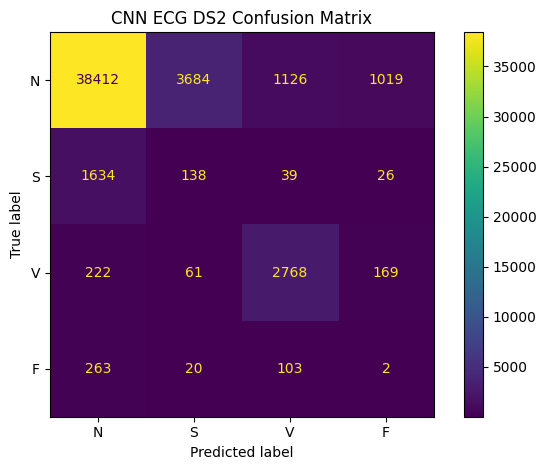

Saved: /Users/janusaban/Documents/ML_research/05_ecg-ml/results/figures/cnn_ECG_ds2_cm.png


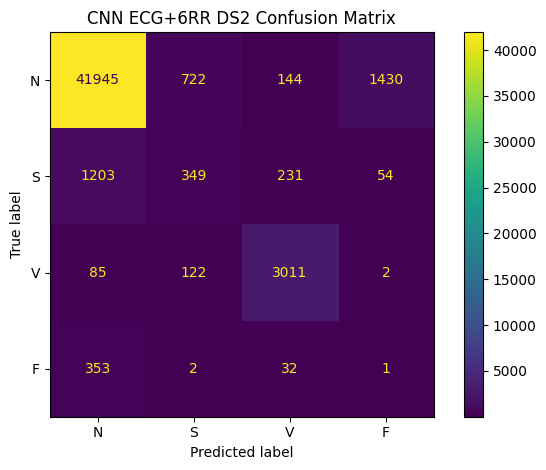

Saved: /Users/janusaban/Documents/ML_research/05_ecg-ml/results/figures/cnn_ECG_plus_6RR_ds2_cm.png


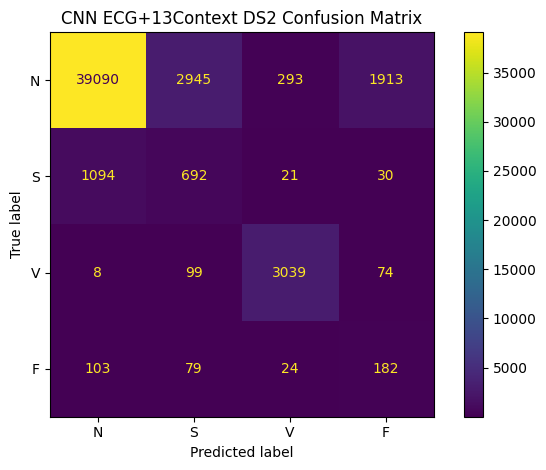

Saved: /Users/janusaban/Documents/ML_research/05_ecg-ml/results/figures/cnn_ECG_plus_13Context_ds2_cm.png


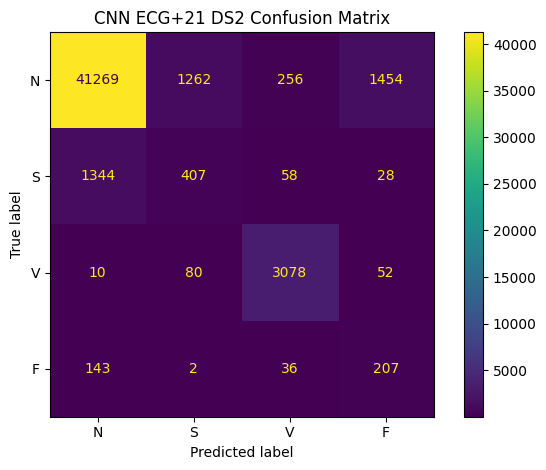

Saved: /Users/janusaban/Documents/ML_research/05_ecg-ml/results/figures/cnn_ECG_plus_21_ds2_cm.png


In [15]:
# ============================================================
# SAVE ONE CONFUSION MATRIX PER CNN STAGE
# ============================================================

for stage_name in STAGE_NAMES:

    cm = confusion_matrix(
        cnn_targets[
            stage_name
        ],

        cnn_predictions[
            stage_name
        ],

        labels=np.arange(
            len(
                CLASS_NAMES
            )
        ),
    )


    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES,
    )


    cm_display.plot(
        values_format="d"
    )


    plt.title(
        f"CNN {stage_name} "
        f"DS2 Confusion Matrix"
    )


    plt.tight_layout()


    safe_stage_name = (
        stage_name
        .replace(
            "+",
            "_plus_"
        )
    )


    figure_path = (
        FIGURES_DIR
        / (
            f"cnn_{safe_stage_name}"
            f"_ds2_cm.png"
        )
    )


    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
    )


    plt.show()


    print(
        "Saved:",
        figure_path
    )

### Save CNN

In [16]:
# ============================================================
# SAVE FOUR FINAL CNN MODELS AND PREPROCESSORS
# ============================================================

CNN_MODEL_DIR = (
    MODELS_DIR
    / "cnn_four_stage"
)


CNN_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# HELPER FOR FILE NAMES
# ============================================================

def safe_stage_name(
    stage_name
):

    return (
        stage_name
        .replace(
            "+",
            "_plus_"
        )
        .replace(
            " ",
            "_"
        )
    )


# ============================================================
# SAVE EACH STAGE
# ============================================================

for stage_name in STAGE_NAMES:

    safe_name = (
        safe_stage_name(
            stage_name
        )
    )


    model = (
        cnn_models[
            stage_name
        ]
    )


    preprocessor = (
        cnn_preprocessors[
            stage_name
        ]
    )


    cv_row = (
        cnn_cv_summary_df[
            cnn_cv_summary_df[
                "stage"
            ]
            == stage_name
        ]
        .iloc[0]
    )


    ds2_row = (
        cnn_results_df[
            cnn_results_df[
                "stage"
            ]
            == stage_name
        ]
        .iloc[0]
    )


    model_path = (
        CNN_MODEL_DIR
        / (
            f"cnn_{safe_name}.pt"
        )
    )


    preprocessor_path = (
        CNN_MODEL_DIR
        / (
            f"cnn_{safe_name}"
            f"_preprocessor.joblib"
        )
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    torch.save(
        {
            "model_state_dict":
                model.state_dict(),

            "model_name":
                "ECGFeatureFusionCNN",

            "stage":
                stage_name,

            "class_names":
                CLASS_NAMES,

            "heartbeat_length":
                255,

            "auxiliary_feature_names":
                CNN_STAGE_DATA[
                    stage_name
                ][
                    "feature_names"
                ],

            "num_auxiliary_features":
                EXPECTED_AUX_DIMENSIONS[
                    stage_name
                ],

            "cv_method":
                "fixed_record_grouped_5_fold",

            "cv_folds":
                N_SPLITS,

            "fold_assignment_file":
                str(
                    FOLD_ASSIGNMENT_PATH
                ),

            "final_training_epochs":
                int(
                    cv_row[
                        "final_epochs"
                    ]
                ),

            "cv_macro_f1_mean":
                float(
                    cv_row[
                        "mean_cv_macro_f1"
                    ]
                ),

            "cv_macro_f1_std":
                float(
                    cv_row[
                        "std_cv_macro_f1"
                    ]
                ),

            "test_accuracy":
                float(
                    ds2_row[
                        "accuracy"
                    ]
                ),

            "test_balanced_accuracy":
                float(
                    ds2_row[
                        "balanced_accuracy"
                    ]
                ),

            "test_macro_f1":
                float(
                    ds2_row[
                        "macro_f1"
                    ]
                ),

            "test_mcc":
                float(
                    ds2_row[
                        "mcc"
                    ]
                ),
        },

        model_path,
    )


    # ========================================================
    # SAVE PREPROCESSOR
    # ========================================================

    joblib.dump(
        {
            "imputer":
                preprocessor[
                    "imputer"
                ],

            "scaler":
                preprocessor[
                    "scaler"
                ],

            "auxiliary_feature_names":
                CNN_STAGE_DATA[
                    stage_name
                ][
                    "feature_names"
                ],
        },

        preprocessor_path,
    )


# ============================================================
# SAVE COMBINED RESULTS
# ============================================================

cnn_results_df.to_csv(
    METRICS_DIR
    / "cnn_four_stage_ds2.csv",
    index=False,
)


cnn_cv_summary_df.to_csv(
    METRICS_DIR
    / "cnn_four_stage_cv_summary.csv",
    index=False,
)


# ============================================================
# COMPLETION SUMMARY
# ============================================================

print("=" * 80)

print(
    "FOUR-STAGE CNN EXPERIMENT COMPLETED"
)

print("=" * 80)


display(
    cnn_results_df
)


print(
    "\nModels saved to:"
)

print(
    CNN_MODEL_DIR
)

FOUR-STAGE CNN EXPERIMENT COMPLETED


,model,stage,auxiliary_features,cv_macro_f1_mean,cv_macro_f1_std,final_epochs,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,CNN,ECG,0,0.417405,0.081371,14,0.831623,0.452037,0.417637,0.452037,0.429944,0.858171,0.380917
1,CNN,ECG+6RR,6,0.539419,0.100784,10,0.911846,0.518939,0.533999,0.518939,0.523413,0.917810,0.588766
2,CNN,ECG+13Context,13,0.552765,0.079759,7,0.865495,0.668283,0.533540,0.668283,0.557928,0.893325,0.526680
3,CNN,ECG+21,21,0.531749,0.061741,5,0.904903,0.660946,0.553558,0.660946,0.573988,0.914594,0.587835



Models saved to:
/Users/janusaban/Documents/ML_research/05_ecg-ml/models/cnn_four_stage
